In [57]:
import numpy as np
import matplotlib.pyplot as plt
import time
from numpy.random import seed
from numpy.random import rand
import sys
import os
import pandas as pd 
from IPython.display import Image, display
import matplotlib.animation as animation

In [2]:
# Se clona el repositorio donde está la implementacion de Berroa
!git clone https://github.com/johnberroa/Ant-Colony-Optimization.git

Cloning into 'Ant-Colony-Optimization'...


In [3]:
# Se agrega la carpeta a la ruta del interpretador:
repo_name = '/Trabajo_1/Parte_2/Ant-Colony-Optimization'
repo_path = os.path.join(os.getcwd(), repo_name)

if repo_path not in sys.path:
    sys.path.append(repo_path)

In [19]:
# 2. Cargar la matriz asegurando index_col=0 y extrayendo .values
ruta_csv = "matriz_costo_total_euros.csv" if os.path.exists("matriz_costo_total_euros.csv") else "Parte_2/matriz_costo_total_euros.csv"
df_costos = pd.read_csv(ruta_csv, index_col=0)
ciudades = list(df_costos.index)
matriz_costos = df_costos.values.astype(float)  # <-- CLAVE: .values
print(f"Dimensiones de la matriz: {matriz_costos.shape}")  # Debe ser (47, 47)
df_costos.head()



Dimensiones de la matriz: (47, 47)


,A Coruña,Albacete,Alicante,Almería,Ávila,Badajoz,Barcelona,Bilbao,Burgos,Cáceres,...,Sevilla,Soria,Tarragona,Teruel,Toledo,Valencia,Valladolid,Vitoria-Gasteiz,Zamora,Zaragoza
A Coruña,0.00,153.58,182.46,205.10,94.23,123.60,196.04,99.54,87.52,118.87,...,164.58,117.86,181.99,167.94,118.72,171.74,78.41,108.47,74.45,142.89
Albacete,153.26,0.00,30.95,61.32,68.11,99.22,95.10,116.46,88.42,93.48,...,90.94,84.90,77.48,58.26,47.03,33.27,83.10,109.48,104.33,78.78
Alicante,182.05,30.88,0.00,50.79,96.90,128.01,97.59,141.39,117.21,122.27,...,111.13,113.69,79.96,70.38,75.81,32.84,111.88,134.51,133.12,90.89
Almería,207.24,60.22,49.58,0.00,119.63,117.15,137.88,174.58,146.54,124.20,...,77.96,143.03,120.25,110.76,93.01,73.13,137.07,167.60,158.30,131.27
Ávila,93.90,67.94,96.82,119.47,0.00,66.39,132.75,76.72,48.79,48.37,...,94.08,51.08,118.70,85.84,28.71,86.10,24.03,69.74,45.07,79.60


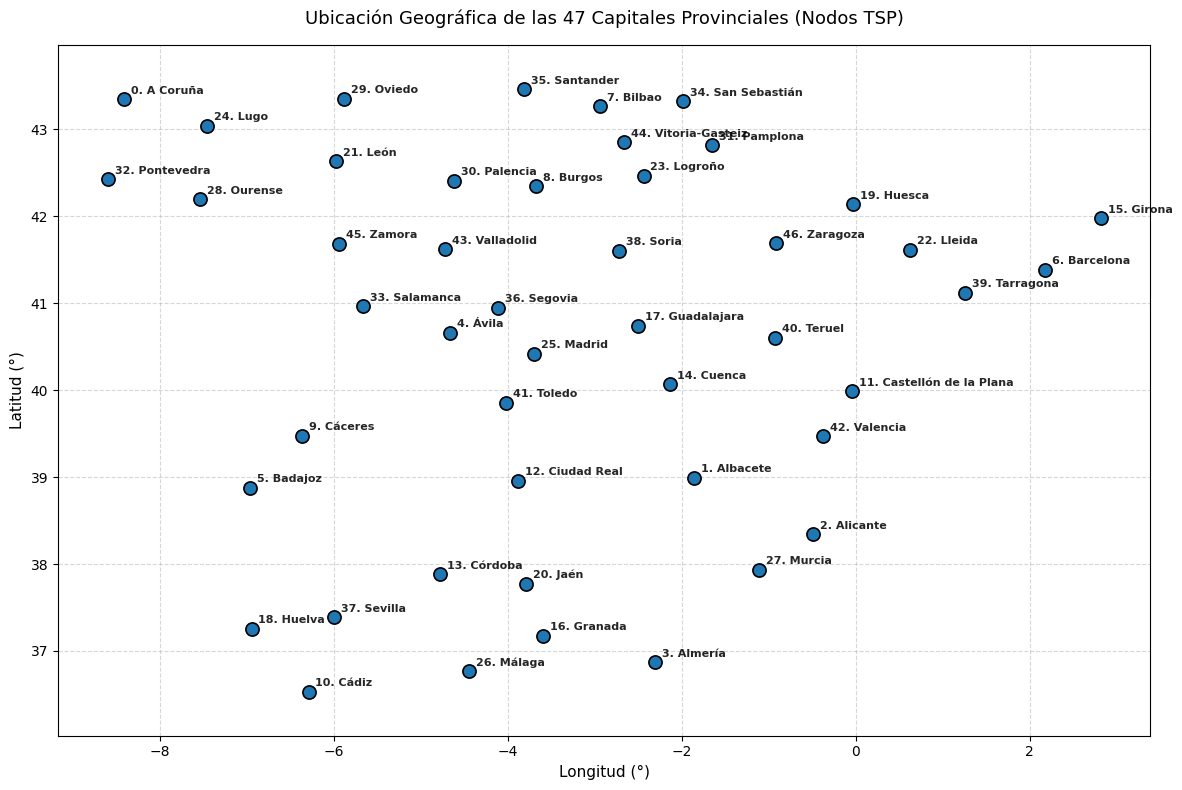

In [20]:
# 1. Cargar coordenadas geográficas
df_coords = pd.read_csv("coordenadas_capitales_espana.csv")

# 2. Configurar la figura del Scatter Plot
plt.figure(figsize=(12, 8))

# 3. Graficar los puntos (Longitud = X, Latitud = Y)
scatter = plt.scatter(
    df_coords["longitud"], 
    df_coords["latitud"], 
    color="#1f77b4", 
    s=90, 
    edgecolors="black", 
    linewidth=1.2, 
    zorder=3
)

# 4. Etiquetar cada ciudad con su nombre e índice
for i, row in df_coords.iterrows():
    plt.annotate(
        f"{i}. {row['ciudad']}",
        (row["longitud"], row["latitud"]),
        textcoords="offset points",
        xytext=(5, 4),
        fontsize=8,
        fontweight="semibold",
        alpha=0.85
    )

# 5. Estética y proporciones
plt.title("Ubicación Geográfica de las 47 Capitales Provinciales (Nodos TSP)", fontsize=13, pad=15)
plt.xlabel("Longitud (°)", fontsize=11)
plt.ylabel("Latitud (°)", fontsize=11)
plt.grid(True, linestyle="--", alpha=0.5)
plt.axis("equal")  # Clave para preservar la relación de aspecto real del mapa
plt.tight_layout()
plt.show()


In [21]:
# 1. Asegurar la inclusión de la librería AntColonyOptimizer en el path
sys.path.append(os.path.abspath("Ant-Colony-Optimization"))
from AntColonyOptimizer import AntColonyOptimizer

Beginning ACO Optimization with 200 iterations...
Best score at iteration 0: 2383.03; overall: 2383.03 (0s)
Best score at iteration 1: 2346.53; overall: 2346.53 (0s)
Best score at iteration 2: 2089.96; overall: 2089.96 (0s)
Best score at iteration 3: 2199.65; overall: 2089.96 (0s)
Best score at iteration 4: 1909.46; overall: 1909.46 (0s)
Best score at iteration 5: 2036.81; overall: 1909.46 (0s)
Best score at iteration 6: 1964.77; overall: 1909.46 (0s)
Best score at iteration 7: 1986.3; overall: 1909.46 (0s)
Best score at iteration 8: 1991.15; overall: 1909.46 (0s)
Best score at iteration 9: 1886.0; overall: 1886.0 (0s)
Best score at iteration 10: 1896.84; overall: 1886.0 (0s)
Best score at iteration 11: 1967.52; overall: 1886.0 (0s)
Best score at iteration 12: 1796.63; overall: 1796.63 (0s)
Best score at iteration 13: 1728.64; overall: 1728.64 (0s)
Best score at iteration 14: 1829.46; overall: 1728.64 (0s)
Best score at iteration 15: 1739.1; overall: 1728.64 (0s)
Best score at iteratio

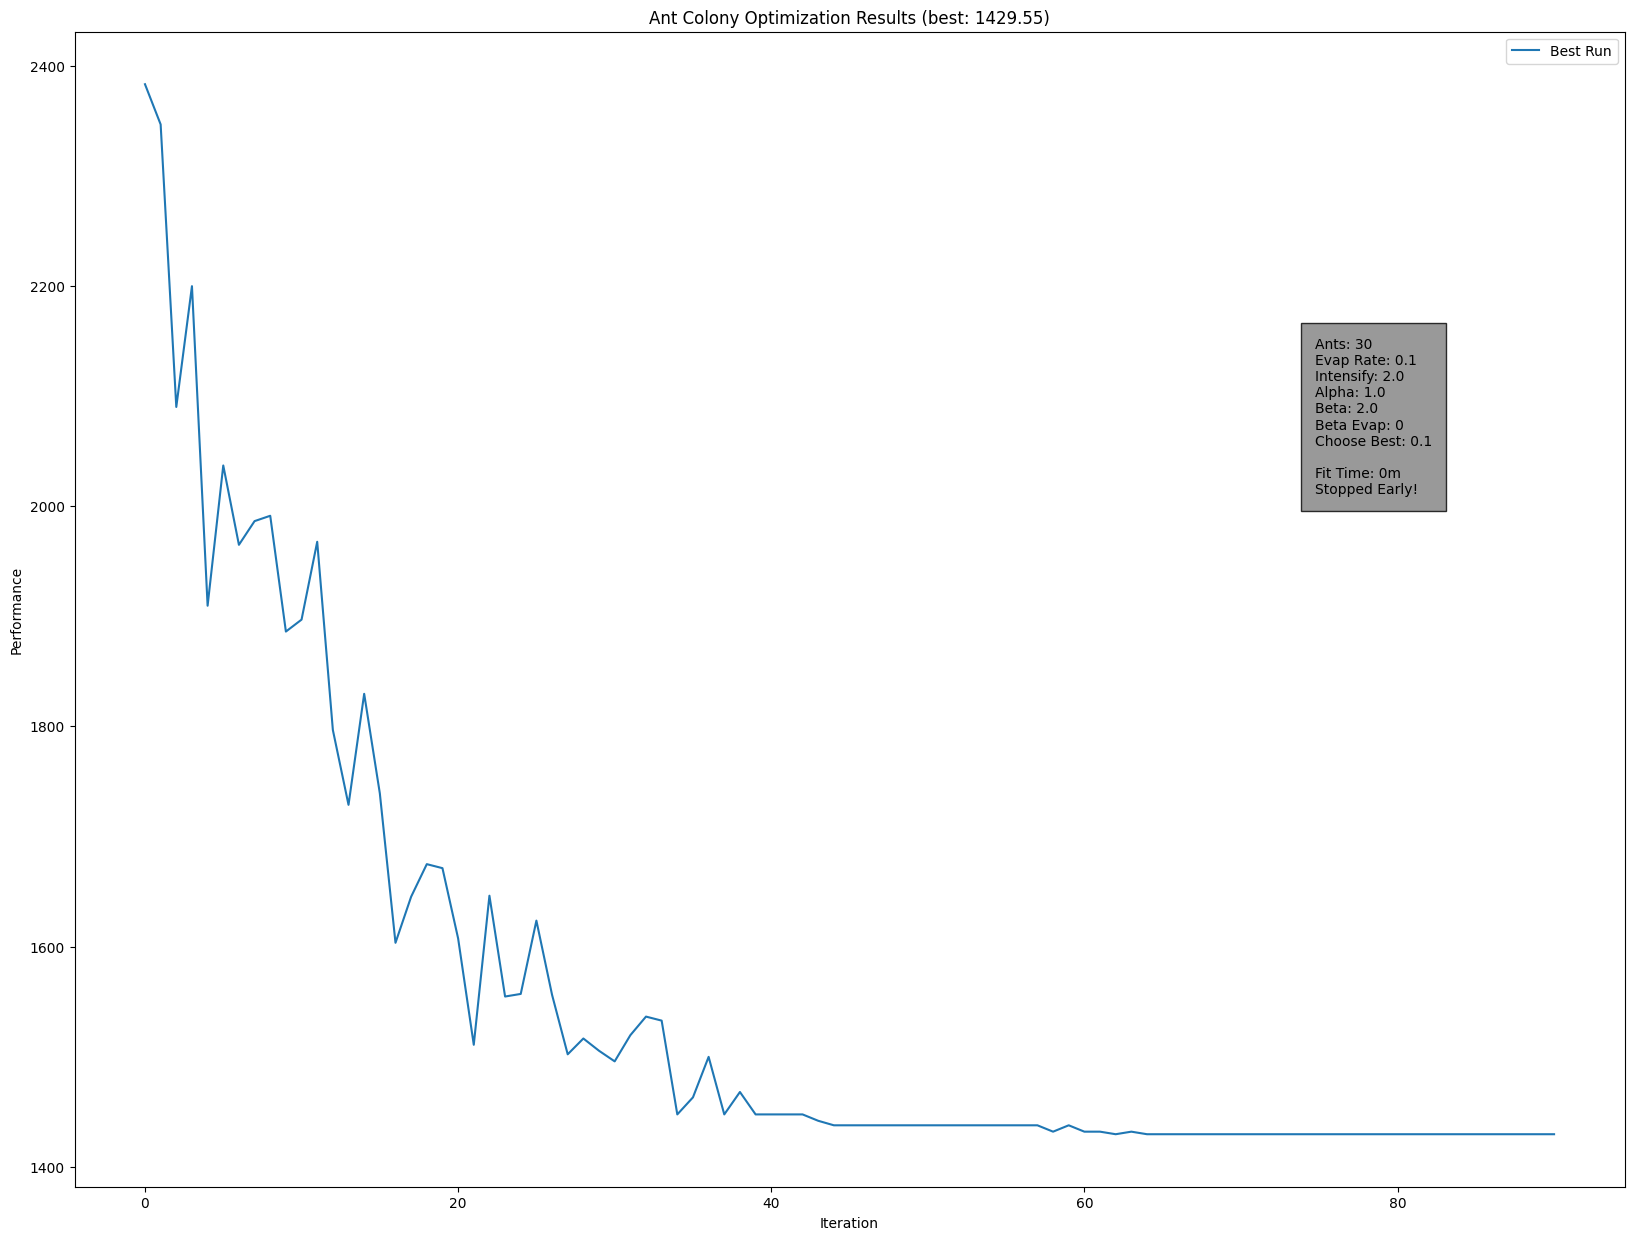

In [52]:
# 3. Instanciar el optimizador
optimizer = AntColonyOptimizer(
    ants=30,                    # Número de hormigas por ciclo
    evaporation_rate=0.1,       # Tasa de evaporación
    intensification=2.0,        # Refuerzo del mejor camino
    alpha=1.0,                  # Importancia de las feromonas
    beta=2.0,                   # Importancia del costo (1 / costo)
    choose_best=0.1             # Probabilidad de selección voraz
)
# 4. Ejecutar la simulación
mejor_costo = optimizer.fit(matriz_costos, iterations=200, mode='min', verbose=True)
print(f"\n🏆 Mejor costo total encontrado: {mejor_costo:.2f} €")
# 5. Graficar la curva de convergencia
optimizer.plot()



In [23]:
# Visualización de la mejor solución
optimizer.best_path

[21,
 24,
 0,
 32,
 28,
 45,
 33,
 9,
 5,
 37,
 18,
 10,
 13,
 20,
 16,
 26,
 3,
 27,
 2,
 1,
 42,
 11,
 39,
 6,
 15,
 22,
 19,
 46,
 40,
 17,
 14,
 25,
 41,
 12,
 4,
 36,
 43,
 30,
 8,
 38,
 23,
 44,
 31,
 34,
 7,
 35,
 29,
 21]

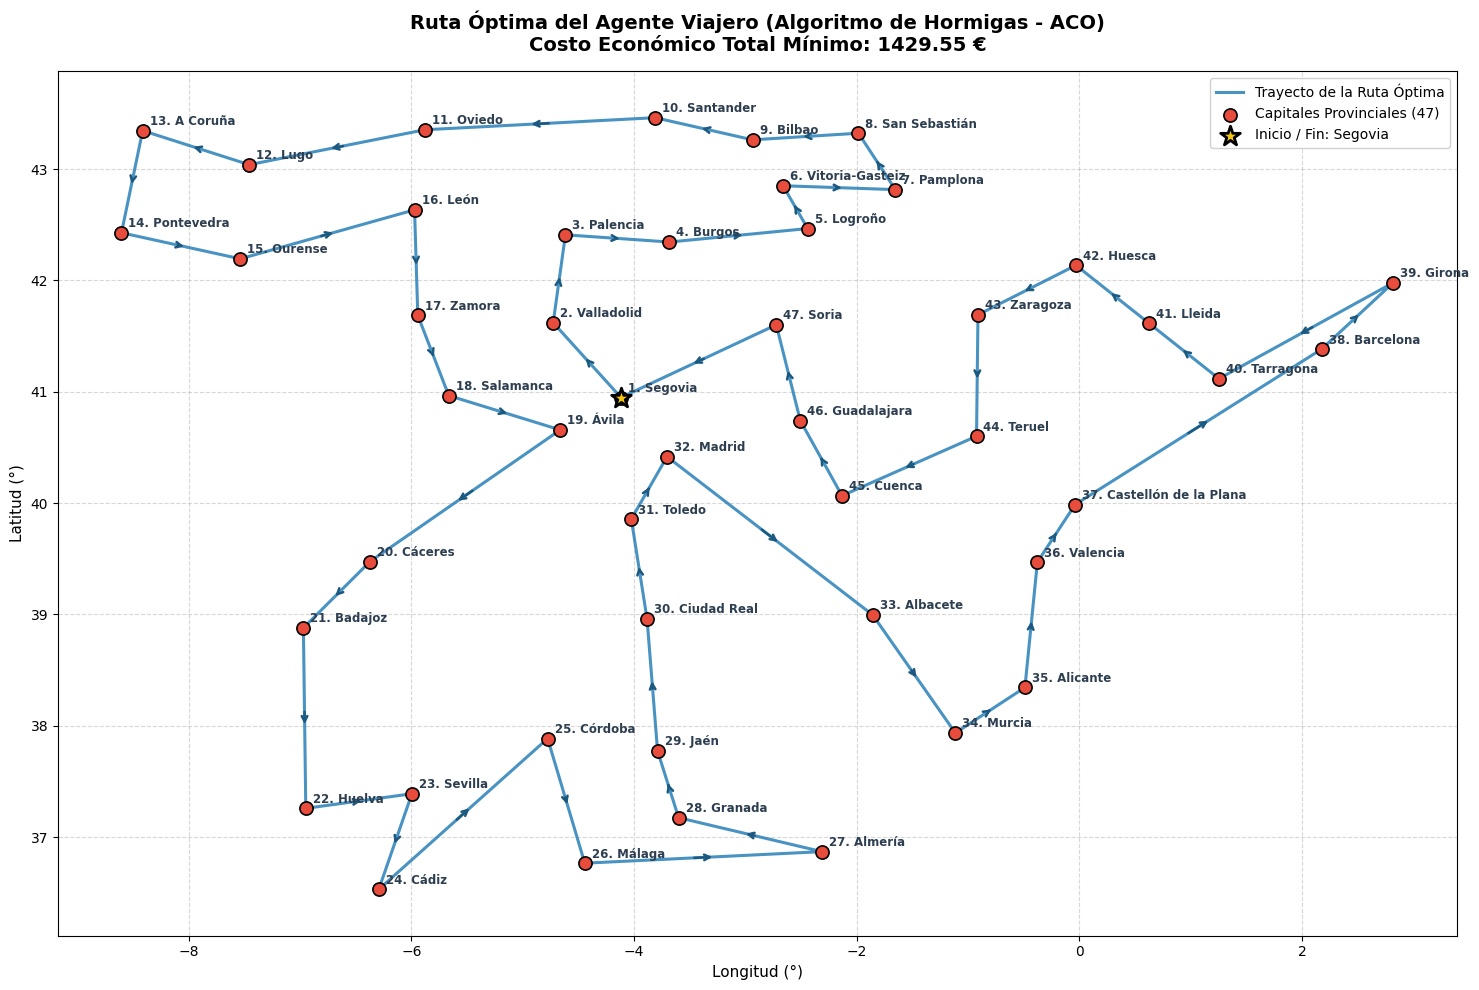

✅ Gráfico generado y guardado como 'ruta_optima_aco_espana.png'


In [53]:
# 1. Cargar las coordenadas geográficas de las capitales
ruta_coords = "coordenadas_capitales_espana.csv" if os.path.exists("coordenadas_capitales_espana.csv") else "Parte_2/coordenadas_capitales_espana.csv"
df_coords = pd.read_csv(ruta_coords)

lons = df_coords["longitud"].values
lats = df_coords["latitud"].values
nombres = df_coords["ciudad"].values

# 2. Extraer la mejor ruta encontrada por el optimizador
mejor_ruta = optimizer.best_path
mejor_costo = optimizer.best

# Asegurar que el ciclo vuelva a la ciudad de inicio
if mejor_ruta[0] != mejor_ruta[-1]:
    mejor_ruta = list(mejor_ruta) + [mejor_ruta[0]]

# Coordenadas ordenadas según el itinerario de la ruta
ruta_lons = [lons[i] for i in mejor_ruta]
ruta_lats = [lats[i] for i in mejor_ruta]

# 3. Configuración del gráfico
plt.figure(figsize=(15, 10))

# Trazar el camino / aristas del recorrido con líneas conectadas
plt.plot(
    ruta_lons, ruta_lats, 
    color="#2980b9", 
    linestyle="-", 
    linewidth=2.2, 
    alpha=0.85, 
    label="Trayecto de la Ruta Óptima", 
    zorder=2
)

# Dibujar flechas para indicar el sentido del viaje
for k in range(len(mejor_ruta) - 1):
    idx_origen = mejor_ruta[k]
    idx_destino = mejor_ruta[k + 1]
    
    # Vector de dirección
    dx = lons[idx_destino] - lons[idx_origen]
    dy = lats[idx_destino] - lats[idx_origen]
    
    # Colocar una pequeña flecha en el punto medio del trayecto
    plt.annotate(
        "", 
        xy=(lons[idx_origen] + 0.55 * dx, lats[idx_origen] + 0.55 * dy),
        xytext=(lons[idx_origen] + 0.45 * dx, lats[idx_origen] + 0.45 * dy),
        arrowprops=dict(arrowstyle="->", color="#1c5980", lw=1.8),
        zorder=3
    )

# 4. Scatter Plot de todas las capitales
plt.scatter(
    lons, lats, 
    color="#e74c3c", 
    s=90, 
    edgecolors="black", 
    linewidth=1.2, 
    label="Capitales Provinciales (47)", 
    zorder=4
)

# 5. Resaltar la ciudad de inicio y fin (Nodo de origen)
idx_inicio = mejor_ruta[0]
plt.scatter(
    lons[idx_inicio], lats[idx_inicio], 
    color="#f1c40f", 
    s=220, 
    edgecolors="black", 
    linewidth=2.0, 
    marker="*", 
    label=f"Inicio / Fin: {nombres[idx_inicio]}", 
    zorder=5
)

# 6. Etiquetar cada ciudad con su orden de visita y nombre
# Creamos un mapa del orden en que se visita cada ciudad
orden_visita = {ciudad_idx: paso + 1 for paso, ciudad_idx in enumerate(mejor_ruta[:-1])}

for idx, nombre in enumerate(nombres):
    paso_num = orden_visita.get(idx, "")
    plt.annotate(
        f"{paso_num}. {nombre}",
        (lons[idx], lats[idx]),
        textcoords="offset points",
        xytext=(5, 4),
        fontsize=8.5,
        fontweight="semibold",
        color="#2c3e50",
        zorder=6
    )

# 7. Título, ejes y proporciones cartográficas
plt.title(
    f"Ruta Óptima del Agente Viajero (Algoritmo de Hormigas - ACO)\n"
    f"Costo Económico Total Mínimo: {mejor_costo:.2f} €", 
    fontsize=14, 
    pad=15, 
    fontweight="bold"
)
plt.xlabel("Longitud (°)", fontsize=11)
plt.ylabel("Latitud (°)", fontsize=11)
plt.grid(True, linestyle="--", alpha=0.5)
plt.axis("equal")  # Mantiene las proporciones geográficas reales de la península
plt.legend(loc="upper right", fontsize=10, framealpha=0.9)

# Guardar la imagen en alta resolución
plt.tight_layout()
plt.savefig("ruta_optima_aco_espana.png", dpi=300, bbox_inches="tight")
plt.show()

print("✅ Gráfico generado y guardado como 'ruta_optima_aco_espana.png'")


In [54]:
print("=" * 60)
print(f"  ITINERARIO DE LA MEJOR RUTA ENCONTRADA POR ACO ({mejor_costo:.2f} €)")
print("=" * 60)

costo_acumulado = 0.0
for paso in range(len(mejor_ruta) - 1):
    origen = mejor_ruta[paso]
    destino = mejor_ruta[paso + 1]
    costo_tramo = matriz_costos[origen, destino]
    costo_acumulado += costo_tramo
    print(f"Paso {paso + 1:02d}: {nombres[origen]:<22} ➔  {nombres[destino]:<22} | Costo tramo: {costo_tramo:6.2f} € | Acum: {costo_acumulado:7.2f} €")

print("=" * 60)


  ITINERARIO DE LA MEJOR RUTA ENCONTRADA POR ACO (1429.55 €)
Paso 01: Segovia                ➔  Valladolid             | Costo tramo:  21.04 € | Acum:   21.04 €
Paso 02: Valladolid             ➔  Palencia               | Costo tramo:  23.07 € | Acum:   44.11 €
Paso 03: Palencia               ➔  Burgos                 | Costo tramo:  17.57 € | Acum:   61.68 €
Paso 04: Burgos                 ➔  Logroño                | Costo tramo:  23.67 € | Acum:   85.35 €
Paso 05: Logroño                ➔  Vitoria-Gasteiz        | Costo tramo:  23.19 € | Acum:  108.54 €
Paso 06: Vitoria-Gasteiz        ➔  Pamplona               | Costo tramo:  18.53 € | Acum:  127.07 €
Paso 07: Pamplona               ➔  San Sebastián          | Costo tramo:  16.66 € | Acum:  143.73 €
Paso 08: San Sebastián          ➔  Bilbao                 | Costo tramo:  19.95 € | Acum:  163.68 €
Paso 09: Bilbao                 ➔  Santander              | Costo tramo:  19.98 € | Acum:  183.66 €
Paso 10: Santander              ➔  Ovie

In [31]:
opt_explorador = AntColonyOptimizer(
    ants=50,                # Más hormigas
    evaporation_rate=0.05,  # Evapora más lento
    intensification=1.5,
    alpha=1.0, 
    beta=2.0, 
    choose_best=0.0         # 100% ruleta probabilística
)
costo_explorador = opt_explorador.fit(matriz_costos, iterations=200, verbose=False)


In [45]:
opt_base = AntColonyOptimizer(
    ants=30, 
    evaporation_rate=0.1, 
    intensification=2.0, 
    alpha=1.0, 
    beta=2.5, 
    choose_best=0.1
)
costo_base = opt_base.fit(matriz_costos, iterations=200, verbose=False)


In [33]:
opt_voraz = AntColonyOptimizer(
    ants=20, 
    evaporation_rate=0.2,   # Evapora más rápido
    intensification=3.0, 
    alpha=1.5, 
    beta=4.5,               # Heurística muy fuerte (muy sensible al costo)
    choose_best=0.25        # 25% de decisiones puramente voraces
)
costo_voraz = opt_voraz.fit(matriz_costos, iterations=200, verbose=False)


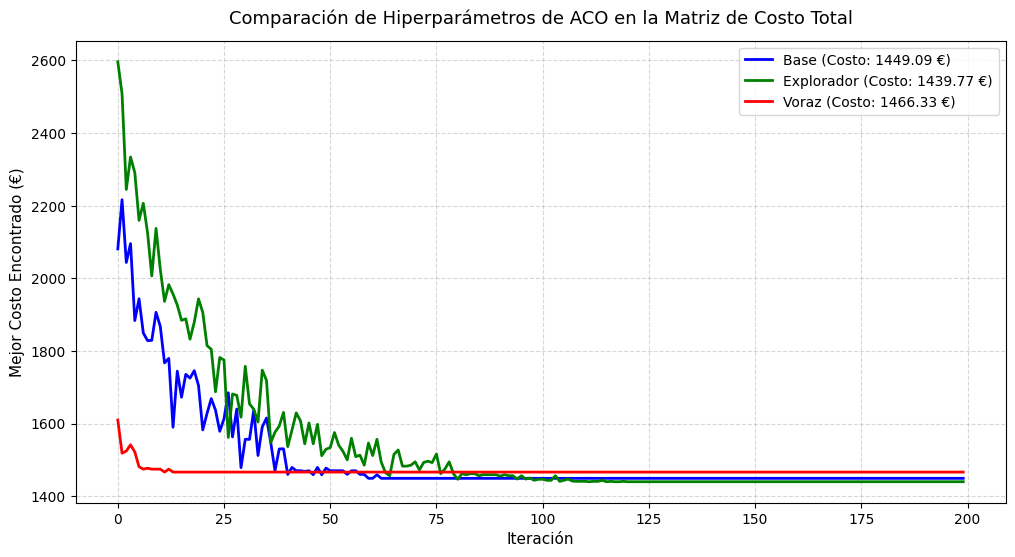

In [46]:
plt.figure(figsize=(12, 6))

plt.plot(opt_base.best_series, label=f"Base (Costo: {opt_base.best:.2f} €)", color="blue", linewidth=2)
plt.plot(opt_explorador.best_series, label=f"Explorador (Costo: {opt_explorador.best:.2f} €)", color="green", linewidth=2)
plt.plot(opt_voraz.best_series, label=f"Voraz (Costo: {opt_voraz.best:.2f} €)", color="red", linewidth=2)

plt.title("Comparación de Hiperparámetros de ACO en la Matriz de Costo Total", fontsize=13, pad=12)
plt.xlabel("Iteración", fontsize=11)
plt.ylabel("Mejor Costo Encontrado (€)", fontsize=11)
plt.grid(True, linestyle="--", alpha=0.5)
plt.legend(fontsize=10)
plt.show()


⏳ Renderizando animación de la ruta óptima...
✅ ¡GIF generado exitosamente con el nombre: 'recorrido_optimo_tsp.gif'!


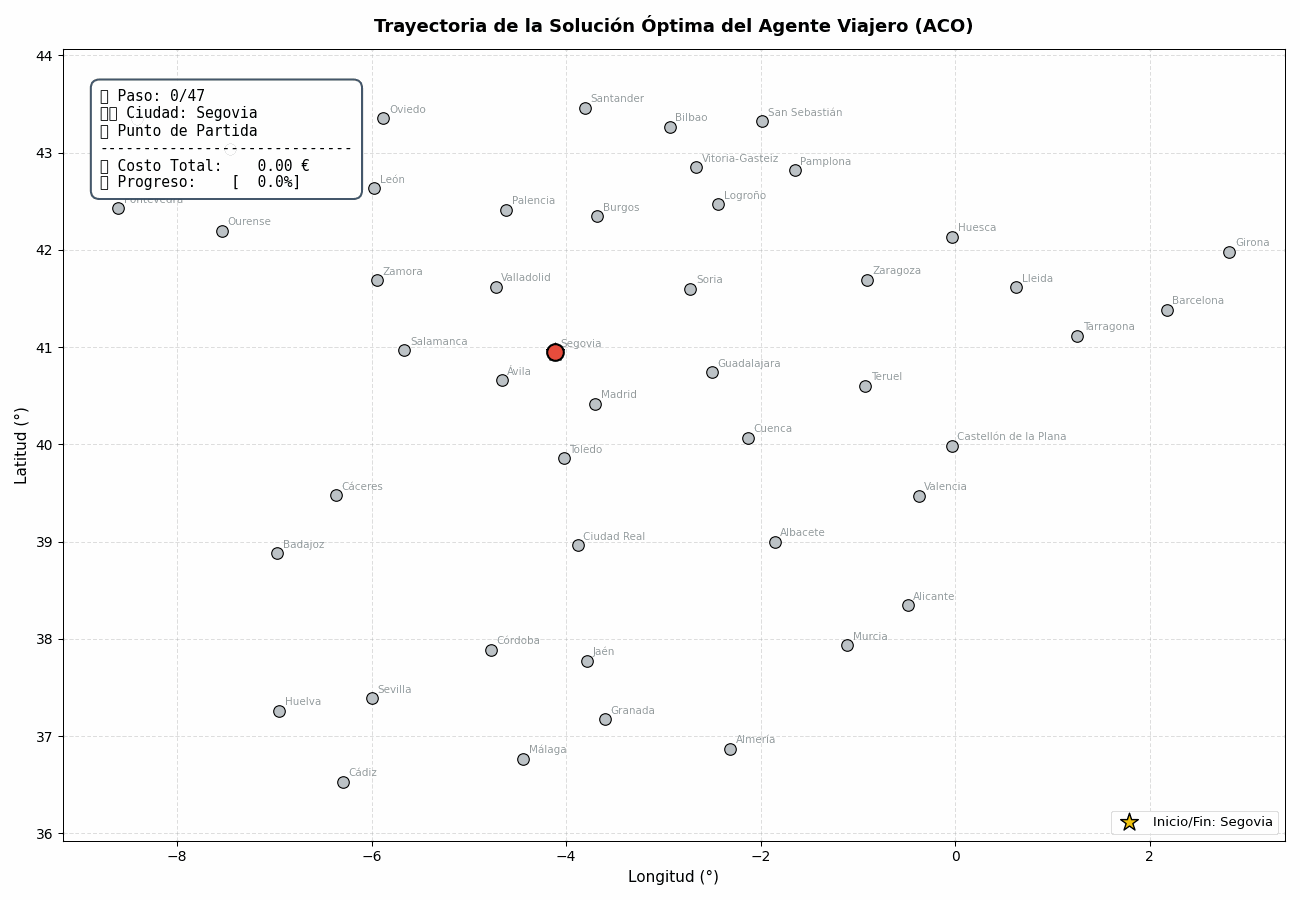

In [58]:
# 1. Cargar coordenadas y matriz de costos
ruta_coords = "coordenadas_capitales_espana.csv" if os.path.exists("coordenadas_capitales_espana.csv") else "Parte_2/coordenadas_capitales_espana.csv"
df_coords = pd.read_csv(ruta_coords)

lons = df_coords["longitud"].values
lats = df_coords["latitud"].values
ciudades = df_coords["ciudad"].values

# 2. Obtener la mejor ruta (cerrando el ciclo)
mejor_ruta = optimizer.best_path
if mejor_ruta[0] != mejor_ruta[-1]:
    mejor_ruta = list(mejor_ruta) + [mejor_ruta[0]]

N_pasos = len(mejor_ruta)  # 48 puntos (47 ciudades + regreso al origen)

# 3. Precalcular los costos acumulados paso a paso
costos_tramos = [0.0]
costos_acumulados = [0.0]

for k in range(N_pasos - 1):
    c_origen = mejor_ruta[k]
    c_destino = mejor_ruta[k + 1]
    costo_tramo = matriz_costos[c_origen, c_destino]
    costos_tramos.append(costo_tramo)
    costos_acumulados.append(costos_acumulados[-1] + costo_tramo)

# 4. Configurar la figura de Matplotlib
fig, ax = plt.subplots(figsize=(13, 9))

# Fondo: Nodos fijos de las 47 ciudades
ax.scatter(lons, lats, color="#bdc3c7", s=70, edgecolors="black", linewidth=0.8, zorder=2)

for i, (nombre, lat, lon) in enumerate(zip(ciudades, lats, lons)):
    ax.annotate(nombre, (lon, lat), textcoords="offset points", xytext=(4, 4), 
                fontsize=7.5, color="#7f8c8d", alpha=0.85, zorder=3)

# Resaltar la ciudad de inicio/fin con una estrella dorada
inicio_idx = mejor_ruta[0]
ax.scatter(lons[inicio_idx], lats[inicio_idx], color="#f1c40f", s=180, 
           edgecolors="black", marker="*", zorder=6, label=f"Inicio/Fin: {ciudades[inicio_idx]}")

# Elementos dinámicos que se actualizarán en cada frame del GIF:
# - Línea del trayecto recorrido
linea_ruta, = ax.plot([], [], color="#2980b9", lw=2.2, alpha=0.85, zorder=4)
# - Marcador móvil de la posición actual del viajero
punto_actual, = ax.plot([], [], marker="o", color="#e74c3c", markersize=12, 
                        markeredgecolor="black", markeredgewidth=1.5, zorder=7)
# - Puntos visitados que se iluminan
puntos_visitados, = ax.plot([], [], marker="o", color="#27ae60", markersize=8, 
                            linestyle="", markeredgecolor="black", zorder=5)

# Panel de información en pantalla (Marcador de costos)
caja_info = ax.text(
    0.03, 0.95, "", transform=ax.transAxes, fontsize=10.5, verticalalignment="top",
    fontfamily="monospace",
    bbox=dict(boxstyle="round,pad=0.6", facecolor="#ffffff", edgecolor="#34495e", lw=1.5, alpha=0.92),
    zorder=10
)

ax.set_title("Trayectoria de la Solución Óptima del Agente Viajero (ACO)", fontsize=13, pad=12, fontweight="bold")
ax.set_xlabel("Longitud (°)", fontsize=11)
ax.set_ylabel("Latitud (°)", fontsize=11)
ax.grid(True, linestyle="--", alpha=0.4)
ax.axis("equal")
ax.legend(loc="lower right", fontsize=9.5)
plt.tight_layout()

# 5. Función de actualización para cada fotograma (frame)
def actualizar(frame):
    # Sub-ruta recorrida hasta este fotograma
    sub_indices = mejor_ruta[:frame + 1]
    sub_lons = [lons[idx] for idx in sub_indices]
    sub_lats = [lats[idx] for idx in sub_indices]
    
    # Actualizar la línea y los puntos
    linea_ruta.set_data(sub_lons, sub_lats)
    puntos_visitados.set_data(sub_lons[:-1], sub_lats[:-1])
    
    # Posición actual del viajero
    nodo_actual = mejor_ruta[frame]
    punto_actual.set_data([lons[nodo_actual]], [lats[nodo_actual]])
    
    # Texto del marcador dinámico
    nombre_actual = ciudades[nodo_actual]
    costo_tramo = costos_tramos[frame]
    acumulado = costos_acumulados[frame]
    
    if frame == 0:
        tramo_str = "Punto de Partida"
    elif frame == N_pasos - 1:
        tramo_str = f"Regreso al inicio (+{costo_tramo:.2f} €)"
    else:
        tramo_str = f"Tramo: +{costo_tramo:.2f} €"

    progreso = (frame / (N_pasos - 1)) * 100
    
    texto = (
        f"📍 Paso: {frame}/{N_pasos - 1}\n"
        f"🏙️ Ciudad: {nombre_actual}\n"
        f"💶 {tramo_str}\n"
        f"-----------------------------\n"
        f"💰 Costo Total: {acumulado:7.2f} €\n"
        f"📊 Progreso:    [{progreso:5.1f}%]"
    )
    caja_info.set_text(texto)
    
    return linea_ruta, punto_actual, puntos_visitados, caja_info

# 6. Compilar la animación y guardarla como GIF (2 fotogramas por segundo)
print("⏳ Renderizando animación de la ruta óptima...")
# Añadimos 6 fotogramas adicionales al final para pausar la vista en el resultado completo
frames_con_pausa = list(range(N_pasos)) + [N_pasos - 1] * 6

anim = animation.FuncAnimation(
    fig, 
    actualizar, 
    frames=frames_con_pausa, 
    interval=500,     # 500 ms por paso (2 ciudades por segundo)
    blit=True
)

nombre_gif = "recorrido_optimo_tsp.gif"
anim.save(nombre_gif, writer=animation.PillowWriter(fps=2))
plt.close(fig)  # Cerrar la figura estática

print(f"✅ ¡GIF generado exitosamente con el nombre: '{nombre_gif}'!")

# 7. Mostrar el GIF directamente en el notebook
display(Image(filename=nombre_gif))
